# Step 3 -- equivalent width vs. the closed-form linear-regime formula

Goal: validate `equivalent_width.measure_ew` against the analytic EW formula derived
in NOTES_perso.tex for a weak (optically thin) line:

`W_linear = pi * r_e * N * f * lambda_rest**2` (independent of b)

where `r_e` is the classical electron radius. This is a clean,
noise-free, closed-form ground truth -- no fitting involved.

In [1]:
import numpy as np

from spectral_diag.constants import C_KMS
from spectral_diag.data_classes import Line
from spectral_diag.line_profiles import optical_depth_gaussian, TAU0_CONST
from spectral_diag.equivalent_width import measure_ew

line = Line(species="Test", wave_rest=1550.0, f=0.1, gamma=2.65e8)

## Test 1 -- numeric EW matches the analytic linear-regime formula

Use a weak line (small logN, so tau << 1 everywhere) and a wide, fine
wavelength grid so the trapezoidal integral captures the full line
area accurately.

In [2]:
logN = 11.0
N = 10**logN
b = 10.0

wave = np.linspace(1200, 1800, 200_000)
tau = optical_depth_gaussian(wave, line, logN=logN, b=b, z=0.0)
print("max tau (should be << 1 for the linear regime):", tau.max())

flux = np.exp(-tau)
continuum = np.ones_like(wave)

W, _ = measure_ew(wave, flux, continuum)
W_analytic = TAU0_CONST * np.sqrt(np.pi) * N * line.f * line.wave_rest**2 / C_KMS

rel_diff = abs(W - W_analytic) / W_analytic
print(f"W numeric  = {W:.6e}")
print(f"W analytic = {W_analytic:.6e}")
print(f"relative difference = {rel_diff:.4%}")
assert rel_diff < 0.01, "numeric EW should match the analytic linear-regime formula to ~1%"
print("PASS: measure_ew matches the closed-form linear-regime EW formula.")

max tau (should be << 1 for the linear regime): 0.0023208601650992326
W numeric  = 2.125146e-04
W analytic = 2.126890e-04
relative difference = 0.0820%
PASS: measure_ew matches the closed-form linear-regime EW formula.


## Test 2 -- W is (almost) independent of b in the linear regime

The derivation shows b cancels out of the linear-regime formula
entirely. Check that numerically: measuring the same weak line at
several different b values should give (almost) the same W, even
though the line's shape (width/depth) is very different each time.

In [3]:
Ws = []
for b_test in [3.0, 10.0, 30.0, 60.0]:
    tau_b = optical_depth_gaussian(wave, line, logN=logN, b=b_test, z=0.0)
    flux_b = np.exp(-tau_b)
    W_b, _ = measure_ew(wave, flux_b, continuum)
    Ws.append(W_b)
    print(f"b={b_test:5.1f} km/s -> W={W_b:.6e}")

Ws = np.array(Ws)
spread = (Ws.max() - Ws.min()) / Ws.mean()
print(f"\nrelative spread across b values: {spread:.4%}")
assert spread < 0.01, "W should be ~independent of b in the linear (unsaturated) regime"
print("PASS: EW is independent of b in the linear regime, as derived.")

b=  3.0 km/s -> W=2.121085e-04
b= 10.0 km/s -> W=2.125146e-04
b= 30.0 km/s -> W=2.126309e-04
b= 60.0 km/s -> W=2.126599e-04

relative spread across b values: 0.2595%
PASS: EW is independent of b in the linear regime, as derived.


## Test 3 -- where the linear formula stops working

The linear formula assumes tau << 1. Raise N and compare it to the
numerically integrated EW of the full Voigt profile: the two should
agree for weak lines, then the true EW should fall below the linear
prediction once the core saturates, and finally rise again as
sqrt(N) when the damping wings take over. This is the curve of
growth.

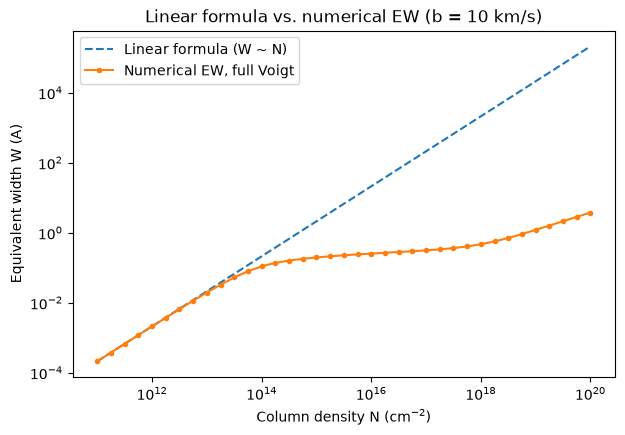

W_numeric / W_linear at logN=11: 0.9992
W_numeric / W_linear at logN=15: 0.0926
log-log slope, weakest lines  : 0.997 (linear regime expects 1)
log-log slope, strongest lines: 0.496 (damped regime expects 0.5)
PASS: linear at low N, below the linear formula once saturated, sqrt(N) when damped.


In [4]:
import matplotlib.pyplot as plt
from spectral_diag.line_profiles import optical_depth

logNs = np.arange(11.0, 20.01, 0.25)
W_numeric = []
for logN_i in logNs:
    tau_i = optical_depth(wave, line, logN=logN_i, b=b, z=0.0)
    W_i, _ = measure_ew(wave, np.exp(-tau_i), continuum)
    W_numeric.append(W_i)
W_numeric = np.array(W_numeric)
W_linear = TAU0_CONST * np.sqrt(np.pi) * 10**logNs * line.f * line.wave_rest**2 / C_KMS

plt.figure(figsize=(7, 4.5))
plt.loglog(10**logNs, W_linear, "--", label="Linear formula (W ~ N)")
plt.loglog(10**logNs, W_numeric, "o-", ms=3, label="Numerical EW, full Voigt")
plt.xlabel("Column density N (cm$^{-2}$)")
plt.ylabel("Equivalent width W (A)")
plt.title(f"Linear formula vs. numerical EW (b = {b:.0f} km/s)")
plt.legend()
plt.show()

ratio = W_numeric / W_linear
slope_low = np.polyfit(logNs[:5], np.log10(W_numeric[:5]), 1)[0]
slope_high = np.polyfit(logNs[-5:], np.log10(W_numeric[-5:]), 1)[0]
print(f"W_numeric / W_linear at logN={logNs[0]:.0f}: {ratio[0]:.4f}")
print(f"W_numeric / W_linear at logN=15: {ratio[np.argmin(abs(logNs - 15))]:.4f}")
print(f"log-log slope, weakest lines  : {slope_low:.3f} (linear regime expects 1)")
print(f"log-log slope, strongest lines: {slope_high:.3f} (damped regime expects 0.5)")
assert abs(ratio[0] - 1) < 0.01
assert abs(slope_low - 1) < 0.02
assert abs(slope_high - 0.5) < 0.05
print("PASS: linear at low N, below the linear formula once saturated, sqrt(N) when damped.")

## Next step

Repeat this kind of check for the saturated and damped regimes once
`curve_of_growth.py` exists (there, W is *not* independent of b, and the
W ~ sqrt(N) damped-regime scaling becomes the thing to validate).